# 02 — Load, clean and prepare offline data

Builds the network-free corpora that notebook 03 and `sandbox datasets prepare` use.

| Source | Input | Output under `data/runtime/prepared/` |
| --- | --- | --- |
| Fixture catalog | `data/fixtures/manifest.csv` + the text files it names | `fixtures_prepared.jsonl` |
| HF mini slice | `data/fixtures/hf/docclass_mini.jsonl` | `hf_prepared.jsonl` |
| Agent gold | `data/fixtures/agents/*.jsonl` | `agents/<agent>_prepared.jsonl` |
| Sorter pilot | first fixture of each document class | `sorter_pilot_balanced.jsonl` |
| Run summary | all of the above | `prep_manifest.json` |

**Cleaning rules:** CRLF → LF, runs of spaces and tabs → one space, three or more newlines → one blank line, and trimmed ends. A row is **dropped** if a required key is missing, its file is missing, or it is empty after cleaning. A malformed `expected_fields` value is logged and replaced with `{}`.

**Cost:** none. Tracked fixtures are only read. Writes go to `data/runtime/`, which is gitignored. Rerunning gives the same fingerprint.

**Prerequisite:** notebook [01](01_offline_environment_setup.ipynb), or an existing `.env` and a profile that activates.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

# Works with or without `pip install -e .`: fall back to the checkout's src/ when needed.
try:
    import mailroom_sandbox  # noqa: F401
except ModuleNotFoundError:
    for parent in (Path.cwd(), *Path.cwd().parents):
        if (parent / "src" / "mailroom_sandbox").is_dir():
            sys.path.insert(0, str(parent / "src"))
            break
    import mailroom_sandbox  # noqa: F401

from mailroom_sandbox.notebook import bootstrap

ctx = bootstrap()
print(json.dumps(ctx.as_dict(), indent=2))

{
  "root": "/private/tmp/mailroom-pr384-fix",
  "profile": "ollama",
  "mock": true,
  "observability": "none",
  "data_dir": "/private/tmp/notebook-demos-03gnk3ib/data",
  "prepared_dir": "/private/tmp/notebook-demos-03gnk3ib/data/runtime/prepared",
  "experiment_log": "/tmp/notebook-demos-03gnk3ib/log/experiment_log.jsonl"
}


In [2]:
try:
    import pandas as pd
except ImportError as exc:  # pragma: no cover - guidance for a bare [dev] install
    raise ImportError('pandas is missing: pip install -e ".[dev,notebooks]"') from exc

pd.set_option("display.max_colwidth", 80)
print(f"pandas {pd.__version__}")


pandas 3.1.1


## 1. The raw fixture catalog

`load_manifest()` reads `data/fixtures/manifest.csv` as is. Each row names a fixture file by `subdir` and `filename`, and carries the expected class, the expected pipeline stage and, optionally, gold fields as JSON.

In [3]:
from mailroom_sandbox.datasets import load_manifest

raw = load_manifest()
raw_df = pd.DataFrame(raw)
print(f"{len(raw_df)} catalog rows, {raw_df['expected_doc_class'].nunique()} classes")
display(raw_df[["id", "subdir", "filename", "expected_doc_class", "expected_stage", "size_tier"]])

11 catalog rows, 6 classes


,id,subdir,filename,expected_doc_class,expected_stage,size_tier
0,contract_msa,contract,sample_msa.txt,contract,archived,small
1,contract_nda,contract,sample_nda.txt,contract,archived,small
2,compliance_10k,compliance_filing,sample_10k.txt,compliance_filing,review,medium
3,compliance_state,compliance_filing,sample_state_filing.txt,compliance_filing,review,small
4,corporate_bylaws,corporate_record,sample_bylaws.txt,corporate_record,archived,medium
5,corporate_resolution,corporate_record,sample_resolution.txt,corporate_record,archived,small
6,correspondence_demand,correspondence,sample_demand_letter.txt,correspondence,archived,small
7,correspondence_memo,correspondence,sample_internal_memo.txt,correspondence,archived,small
8,ambiguous_01,ambiguous,mixed_memo.txt,correspondence,review,small
9,insurance_claim,insurance_claim,sample_claim.txt,insurance_claim,archived,small


In [4]:
pd.concat(
    {
        "class": raw_df["expected_doc_class"].value_counts(),
        "stage": raw_df["expected_stage"].replace("", "(none)").value_counts(),
    }
).rename("rows").to_frame()

rows
class correspondence        3
      contract              2
      compliance_filing     2
      corporate_record      2
      insurance_claim       1
      merger_agreement      1
stage archived              8
      review                3

## 2. What `normalize_text` does

A quick before-and-after example on a messy string. Paragraph breaks are kept. Everything else collapses.

In [5]:
from mailroom_sandbox.prep import normalize_text

messy = "  MASTER   SERVICES\tAGREEMENT\r\n\r\n\r\n\r\nThis  Agreement is made…  \n\n\n"
print("before:", repr(messy))
print("after: ", repr(normalize_text(messy)))

before: '  MASTER   SERVICES\tAGREEMENT\r\n\r\n\r\n\r\nThis  Agreement is made…  \n\n\n'
after:  'MASTER SERVICES AGREEMENT\n\nThis Agreement is made…'


## 3. Clean the fixture catalog and the HF slice

Each cleaner returns `(rows, CleanReport)`. The report counts what was kept, dropped or repaired, and lists one `issues` entry per problem row, so review it before trusting the output.

In [6]:
from mailroom_sandbox.prep import clean_hf_rows, clean_manifest_rows

fixtures, fix_report = clean_manifest_rows()
hf_rows, hf_report = clean_hf_rows()

reports_df = pd.DataFrame([fix_report.as_dict(), hf_report.as_dict()]).set_index("source")
display(reports_df.drop(columns="issues"))
for report in (fix_report, hf_report):
    for issue in report.issues:
        print(f"[{report.source}] {issue}")

assert fix_report.kept_rows > 0, "no fixture rows survived cleaning"
assert hf_report.kept_rows > 0, "the HF mini slice is empty"

,input_rows,kept_rows,dropped_empty,dropped_missing_fields,repaired_fields
source,,,,,
manifest,11,11,0,0,0
hf,7,7,0,0,0


In [7]:
fixtures_df = pd.DataFrame(fixtures)
display(fixtures_df[["id", "expected_doc_class", "expected_stage", "char_count", "path"]])

first = fixtures[0]
print(f"\n{first['id']} ({first['expected_doc_class']}, {first['char_count']} chars):")
print(first["text"][:400], "…")
print("\nexpected_fields:", json.dumps(first["expected_fields"], indent=2)[:400])

,id,expected_doc_class,expected_stage,char_count,path
0,contract_msa,contract,archived,2517,data/fixtures/contract/sample_msa.txt
1,contract_nda,contract,archived,1283,data/fixtures/contract/sample_nda.txt
2,compliance_10k,compliance_filing,review,10131,data/fixtures/compliance_filing/sample_10k.txt
3,compliance_state,compliance_filing,review,984,data/fixtures/compliance_filing/sample_state_filing.txt
4,corporate_bylaws,corporate_record,archived,5745,data/fixtures/corporate_record/sample_bylaws.txt
5,corporate_resolution,corporate_record,archived,1865,data/fixtures/corporate_record/sample_resolution.txt
6,correspondence_demand,correspondence,archived,1986,data/fixtures/correspondence/sample_demand_letter.txt
7,correspondence_memo,correspondence,archived,1653,data/fixtures/correspondence/sample_internal_memo.txt
8,ambiguous_01,correspondence,review,2294,data/fixtures/ambiguous/mixed_memo.txt
9,insurance_claim,insurance_claim,archived,778,data/fixtures/insurance_claim/sample_claim.txt



contract_msa (contract, 2517 chars):
CONFIDENTIAL

MASTER SERVICES AGREEMENT

This Master Services Agreement (this "Agreement") is entered into as of January 15, 2024 (the "Effective Date") by and between:

ACME CORPORATION, a Delaware corporation with its principal place of business at 100 Innovation Drive, Palo Alto, CA 94301 ("Client"),

and

ZENITH TECHNOLOGIES LLC, a California limited liability company with its principal place  …

expected_fields: {
  "parties": [
    "ACME Corporation",
    "Zenith Technologies LLC"
  ],
  "governing_law": "Delaware"
}


In [8]:
hf_df = pd.DataFrame(hf_rows)
display(hf_df[["id", "doc_type", "expected_hf_class", "split", "char_count"]])

,id,doc_type,expected_hf_class,split,char_count
0,hf_contract_01,contract,contract,test,259
1,hf_merger_01,merger_agreement,merger_agreement,test,296
2,hf_corp_01,corporate_record,corporate_record,test,194
3,hf_corr_01,correspondence,correspondence,test,174
4,hf_ins_01,insurance_claim,insurance_claim,test,143
5,hf_ins_property_01,insurance_claim,insurance_claim,test,228
6,hf_ins_auto_01,insurance_claim,insurance_claim,test,299


### Is the gold grounded in the text?

`gold_field_grounding()` checks that each extractive gold value in `expected_fields`, such as a party name or a governing law, appears in the cleaned text (ignoring case and whitespace runs), literally or in a canonical form: an ISO date, an amount by value, a spelled-out numeral or an alias such as `SEC`. Those matches are `grounded_normalized` and listed with the form that matched. A value that is **ungrounded** usually means the gold labels belong to another document. Mock evals echo the gold labels, so only a live run would otherwise expose it. Categorical labels (`communication_type`, `merger_consideration`) are classifications, not quotes, and booleans are not text; both are counted but not checked. This cell is a gate: fix any ungrounded row in `data/fixtures/manifest.csv`.

In [9]:
# Every extractive gold value must be written in its fixture text (case/whitespace-insensitive),
# literally or in a canonical form: ISO dates, amounts by value, spelled-out numerals.
# Categorical labels (communication_type, merger_consideration) are classifications, not spans.
from collections import Counter

from mailroom_sandbox.notebook import (
    agent_fixture_grounding,
    cached_doc_rows,
    gold_field_grounding,
    label_overlay_grounding,
    merged_truth,
    ungrounded,
)

grounding = gold_field_grounding(fixtures) + agent_fixture_grounding()
print(Counter(f.status for f in grounding))
for f in grounding:
    if f.status == "grounded_normalized":
        print(f"normalized ({f.form}) {f.row_id}.{f.field}: {f.value!r}")
missing = ungrounded(grounding)
for f in missing:
    print(f"UNGROUNDED {f.row_id}.{f.field}: {f.value!r}")
assert not missing, "gold values not found in fixture text; fix data/fixtures/manifest.csv or data/fixtures/agents/"

# Scoring overlays (near-gold, interim): each truth label checked by the rule that admitted it
# (stored quote, review rule, derivation, vocabulary). With a pulled Hub corpus
# (`sandbox datasets pull`), labels that stored no quote are checked against their document too.
overlay = label_overlay_grounding(rows=cached_doc_rows())
print(Counter((f.overlay, f.status) for f in overlay))
bad = [f for f in overlay if f.status == "ungrounded"]
for f in bad:
    print(f"UNSUPPORTED {f.overlay} {f.doc_id}.{f.field}: {f.value!r} ({f.reason})")
assert not bad, "overlay labels their evidence does not support; see data/labels/interim/README.md"

# Merged truth (Hub GT -> interim -> near-gold, as scoring merges it): where each scored field
# comes from, how the overlays overlap, and no overlay replacing a Hub label but a correction.
hub_rows = cached_doc_rows()
if hub_rows:
    merge = merged_truth(hub_rows.values())
    for doc_class, sources in merge.breakdown().items():
        print(doc_class, sources)
    for key, n in sorted(merge.overlaps.items(), key=lambda kv: -kv[1]):
        print(f"overlap {key}: {n}")
    # Hub labels an overlay disagrees with that no rule settled: the Hub value stands until a
    # review (or CUAD check) makes the overlay the clear winner, as an interim correction.
    print(f"{len(merge.hub_conflicts)} unsettled Hub conflicts")
    for c in merge.hub_conflicts:
        print(f"  {c.doc_id}.{c.field}: hub={c.hub_value!r} overlay={c.overlay_value!r} "
              f"grounded hub/overlay={c.hub_grounded}/{c.overlay_grounded}")
    assert not merge.violations, merge.violations[:5]


Counter({'grounded': 28, 'categorical': 4, 'grounded_normalized': 2})
normalized (alias) compliance_10k.regulatory_body: 'SEC'
normalized (alias) judge/judge_10k.regulatory_body: 'SEC'


Counter({('interim', 'grounded'): 3651, ('gold-overlay', 'grounded'): 3270, ('gold-overlay', 'in_vocabulary'): 876, ('interim', 'in_vocabulary'): 55})


contract {'hub': 12799, 'near_gold': 900, 'interim': 45}
corporate_record {'hub': 6275, 'interim': 598, 'near_gold': 826, 'interim_correction': 44, 'near_gold_shf010': 36}
correspondence {'near_gold': 4925, 'interim': 2365, 'hub': 20832, 'interim_correction': 55, 'near_gold_shf010': 4}
insurance_claim {'hub': 26100, 'interim': 536}
merger_agreement {'hub': 3496, 'interim': 93}
overlap ('original_header', 'differ', 'interim'): 1763
overlap ('gate_accepted_grounded', 'agree', 'interim'): 615
overlap ('gate_accepted_grounded', 'differ', 'near_gold'): 40
overlap ('original_header', 'agree', 'interim'): 32
30 unsettled Hub conflicts
  DOC-411f6e671db13584.cuad_clauses: hub=None overlay=["Exclusivity: Talent will not endorse or make any appearances or advertisements on behalf of any other product which is directly competitive to ESSI's products.", 'Anti-Assignment: Neither this Agreement nor any of the rights or obligations contained herein may be assigned or transferred by either party with

## 4. Agent gold sets

Every agent fixture keeps its own columns. The cleaner checks that each row has an `id`, parses `expected_fields` given as a JSON string, and attaches normalized fixture text when the row names a `subdir` and `filename`.

In [10]:
from mailroom_sandbox.prep import clean_agent_rows

AGENTS = ["judge", "arbiter", "boss", "intake", "pdf_transcriber", "image_extractor"]
agent_reports = []
for agent in AGENTS:
    rows, report = clean_agent_rows(agent)
    entry = report.as_dict()
    entry["issues"] = len(report.issues)
    entry["with_text"] = sum(1 for r in rows if r.get("text"))
    agent_reports.append(entry)
    for issue in report.issues:
        print(f"[{report.source}] {issue}")

pd.DataFrame(agent_reports).set_index("source")

,input_rows,kept_rows,dropped_empty,dropped_missing_fields,repaired_fields,issues,with_text
source,,,,,,,
agents/judge,2,2,0,0,0,0,2
agents/arbiter,2,2,0,0,0,0,0
agents/boss,2,2,0,0,0,0,0
agents/intake,3,3,0,0,0,0,3
agents/pdf_transcriber,1,1,0,0,0,0,0
agents/image_extractor,1,1,0,0,0,0,0


## 5. Write every prepared artifact

`prepare_offline_datasets()` reruns all cleaners and writes the JSONL files plus `prep_manifest.json`. `sandbox datasets prepare` runs the same function from the CLI.

In [11]:
from mailroom_sandbox.prep import prepare_offline_datasets

summary = prepare_offline_datasets()
print(json.dumps({k: summary[k] for k in ("prepared_at", "fingerprint", "counts", "manifest")}, indent=2))

files = sorted(p for p in ctx.prepared_dir.rglob("*") if p.is_file())
pd.DataFrame(
    {"file": [str(p.relative_to(ctx.prepared_dir)) for p in files], "bytes": [p.stat().st_size for p in files]}
)

{
  "prepared_at": "2026-11-20T12:00:20.124378+00:00",
  "fingerprint": "418eb49b0465",
  "counts": {
    "fixtures": 11,
    "hf": 7,
    "agents": {
      "judge": 2,
      "arbiter": 2,
      "boss": 2,
      "intake": 3,
      "pdf_transcriber": 1,
      "image_extractor": 1
    },
    "sorter_pilot_balanced": 6
  },
  "manifest": "/private/tmp/notebook-demos-03gnk3ib/data/runtime/prepared/prep_manifest.json"
}


,file,bytes
0,agents/arbiter_prepared.jsonl,487
1,agents/boss_prepared.jsonl,357
2,agents/image_extractor_prepared.jsonl,93
3,agents/intake_prepared.jsonl,267
4,agents/judge_prepared.jsonl,13515
5,agents/pdf_transcriber_prepared.jsonl,97
6,fixtures_prepared.jsonl,35662
7,hf_prepared.jsonl,2827
8,prep_manifest.json,2965
9,sorter_pilot_balanced.jsonl,24903


## 6. Validate what was written

`check_prepared_artifacts()` reads every file back from disk. It checks that the counts match the manifest, that ids are unique, that each fixture row has text and a class, that the balanced slice has exactly one row per fixture class, and that the fingerprint recomputes. A second prepare must give the **same fingerprint**, because the fingerprint ties eval records to dataset content.

In [12]:
from mailroom_sandbox.notebook import check_prepared_artifacts

problems = check_prepared_artifacts(summary, ctx.root)
assert not problems, "\n".join(problems)

again = prepare_offline_datasets()
assert again["fingerprint"] == summary["fingerprint"], "prepare is not deterministic"
assert summary["counts"]["fixtures"] == fix_report.kept_rows
print(f"all checks passed; fingerprint {summary['fingerprint']} is stable across reruns")

all checks passed; fingerprint 418eb49b0465 is stable across reruns


## 7. Corpus overview

In [13]:
by_class = (
    fixtures_df.groupby("expected_doc_class")["char_count"]
    .agg(docs="count", mean_chars="mean", min_chars="min", max_chars="max")
    .round(0)
    .astype(int)
    .sort_values("docs", ascending=False)
)
by_class

,docs,mean_chars,min_chars,max_chars
expected_doc_class,,,,
correspondence,3,1978,1653,2294
compliance_filing,2,5558,984,10131
contract,2,1900,1283,2517
corporate_record,2,3805,1865,5745
insurance_claim,1,778,778,778
merger_agreement,1,296,296,296


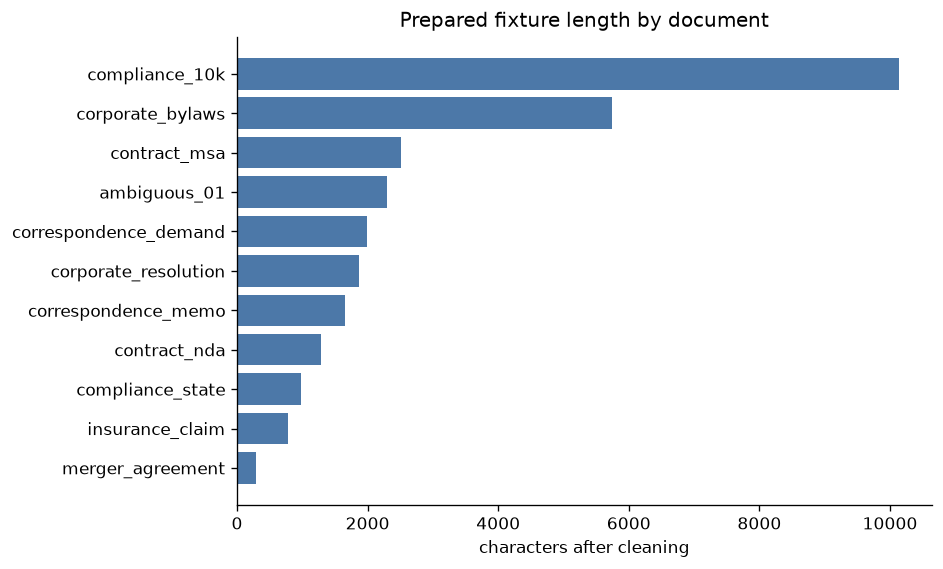

In [14]:
from mailroom_sandbox.notebook import show_figure
import matplotlib.pyplot as plt

ordered = fixtures_df.sort_values("char_count")
fig, ax = plt.subplots(figsize=(8, 0.35 * len(ordered) + 1))
ax.barh(ordered["id"], ordered["char_count"], color="#4C78A8")
ax.set_xlabel("characters after cleaning")
ax.set_title("Prepared fixture length by document")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
show_figure(fig)


**Next:** [`03_offline_sandbox_smoke.ipynb`](03_offline_sandbox_smoke.ipynb) runs mock evals against these files.